### Installing Python Libraries
To install a library, use the `!` prefix followed by `pip install <library_name>`.

For example, to install the `requests` library (or any other package from PyPI):

In [ ]:
%pip install mediapipe xgboost scikit-learn pillow numpy matplotlib tqdm

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 1. Download the zip dataset directly into Colab's local environment
!wget -O dataset.zip "https://data.mendeley.com/public-files/datasets/j4y5w2c8w9/files/28201373-c176-4b20-8f5e-c963d3ca1564/file_downloaded"

# 2. Unzip the file silently into a target folder named 'dataset'
!unzip -q dataset.zip -d dataset/

# 3. Clean up the zip file to save workspace storage
!rm dataset.zip

print("Dataset successfully downloaded and unzipped!")


--2026-10-19 11:54:27--  https://data.mendeley.com/public-files/datasets/j4y5w2c8w9/files/28201373-c176-4b20-8f5e-c963d3ca1564/file_downloaded
Resolving data.mendeley.com (data.mendeley.com)... 162.159.133.86, 162.159.130.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.133.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/7518778b-9eec-4e82-8cc0-249b1a056576 [following]
--2026-10-19 11:54:27--  https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/7518778b-9eec-4e82-8cc0-249b1a056576
Resolving prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)... 52.92.17.234, 3.5.73.1, 3.5.73.37, ...
Connecting to prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)|52.92.17.234|:443... con

In [ ]:
import os
print(os.listdir('dataset'))

['asl_dataset']


In [ ]:
# 1. Install the unrar extraction utility
!apt-get install unrar -y

# 2. Download the RAR dataset directly into Colab
!wget -O dataset.rar "https://data.mendeley.com/public-files/datasets/xs6mvhx6rh/files/8c504c17-1765-4935-9f4f-4a2aa68cb9f0/file_downloaded"

# 3. Extract the RAR file silently into a target folder named 'dataset_rar'
# Note: 'x' extracts with full paths, '-q' runs it quietly
!unrar x dataset.rar dataset_rar/

# 4. Clean up the compressed archive to free up space
!rm dataset.rar

print("RAR Dataset successfully downloaded and extracted!")


Streaming output truncated to the last 5000 lines.
Extracting  dataset_rar/ASLYset/labels/User1/g/User1_G_47.txt             99%  OK 
Extracting  dataset_rar/ASLYset/labels/User1/g/User1_G_48.txt             99%  OK 
Extracting  dataset_rar/ASLYset/labels/User1/g/User1_G_49.txt             99%  OK 
Extracting  dataset_rar/ASLYset/labels/User1/g/User1_G_5.txt              99%  OK 
Extracting  dataset_rar/ASLYset/labels/User1/g/User1_G_50.txt             99%  OK 
Extracting  dataset_rar/ASLYset/labels/User1/g/User1_G_6.txt              99%  OK 
Extracting  dataset_rar/ASLYset/labels/User1/g/User1_G_7.txt              99%  OK 
Extracting  dataset_rar/ASLYset/labels/User1/g/User1_G_8.txt              99%  OK 
Extracting  dataset_rar/ASLYset/labels/User1/g/User1_G_9.txt              99%  OK 
Creating    dataset_rar/ASLYset/labels/User1/h                        OK
Extracting  dataset_rar/ASLYset/labels/User1/h/d

In [ ]:
import os
print(os.listdir('dataset_rar'))

['ASLYset']


In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import mediapipe as mp
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier


TRAIN_ROOT = Path("dataset/asl_dataset")
EXTERNAL_ROOT = Path("dataset_rar/ASLYset/images")

LETTERS = "ABCDEFGHIKLMNOPQRSTUVWXY"
LABEL_MAP = {letter: index for index, letter in enumerate(LETTERS)}

HAND_MODEL = Path("models/hand_landmarker.task")
HAND_MODEL.parent.mkdir(parents=True, exist_ok=True)

MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "hand_landmarker/hand_landmarker/float16/1/"
    "hand_landmarker.task"
)

if not HAND_MODEL.exists():
    urlretrieve(MODEL_URL, HAND_MODEL)

print("MediaPipe model:", HAND_MODEL)

MediaPipe model: models/hand_landmarker.task


In [ ]:
from google.colab import auth
auth.authenticate_user()

BUCKET_NAME = "handspell-asl-models-bucket"

# Run this immediately after training finishes
!gsutil -m cp -r models/ gs://{BUCKET_NAME}/
print("Securely uploaded to GCP before disconnect!")

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying file://models/hand_landmarker.task [Content-Type=application/octet-stream]...
-
Operation completed over 1 objects/7.5 MiB.                                      
Securely uploaded to GCP before disconnect!


In [ ]:
def find_images(root):
    root = Path(root)

    if not root.is_dir():
        raise FileNotFoundError(root)

    paths, labels = [], []

    for path in sorted(root.rglob("*")):
        if not path.is_file():
            continue

        if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue

        letter = path.parent.name.upper()

        if letter in LABEL_MAP:
            paths.append(path)
            labels.append(LABEL_MAP[letter])

    if not paths:
        raise ValueError(f"No images in supported letter folders: {root}")

    return paths, np.array(labels, dtype=np.int64)

In [ ]:
def read_rgb(path):
    with Image.open(path) as original:
        oriented = ImageOps.exif_transpose(original).convert("RGBA")
        background = Image.new(
            "RGBA", oriented.size, (255, 255, 255, 255)
        )
        image = Image.alpha_composite(
            background, oriented
        ).convert("RGB")

        # Limit large images while preserving aspect ratio.
        image.thumbnail((1024, 1024), Image.Resampling.LANCZOS)

        return np.array(image)

In [ ]:
def create_landmarker():
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(HAND_MODEL)
        ),
        running_mode=mp.tasks.vision.RunningMode.IMAGE,
        num_hands=1,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5,
    )

    return mp.tasks.vision.HandLandmarker.create_from_options(options)

In [ ]:
def get_features(rgb, landmarker):
    image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(rgb),
    )

    result = landmarker.detect(image)

    if not result.hand_landmarks:
        return None, None

    points = np.array(
        [[point.x, point.y, point.z]
         for point in result.hand_landmarks[0]],
        dtype=np.float32,
    )

    # Express coordinates in consistent units.
    height, width = rgb.shape[:2]
    points *= np.array([width, height, width], dtype=np.float32)

    # Wrist becomes the origin.
    relative = points - points[0]

    # Normalize by wrist-to-middle-finger-knuckle distance.
    scale = np.linalg.norm(relative[9])

    if scale < 1e-6:
        return None, None

    features = (relative / scale).reshape(-1)

    # 21 points × 3 coordinates = 63 features.
    return features, result.hand_landmarks[0]

In [ ]:
def extract_features(paths):
    # NaN rows preserve failures in their original positions.
    features = np.full((len(paths), 63), np.nan, dtype=np.float32)
    failures = []

    with create_landmarker() as landmarker:
        for index, path in enumerate(tqdm(paths)):
            try:
                rgb = read_rgb(path)
                vector, _ = get_features(rgb, landmarker)

                if vector is None:
                    failures.append((str(path), "No usable hand landmarks"))
                else:
                    features[index] = vector

            except (OSError, ValueError, RuntimeError) as error:
                failures.append((str(path), str(error)))

    return features, failures

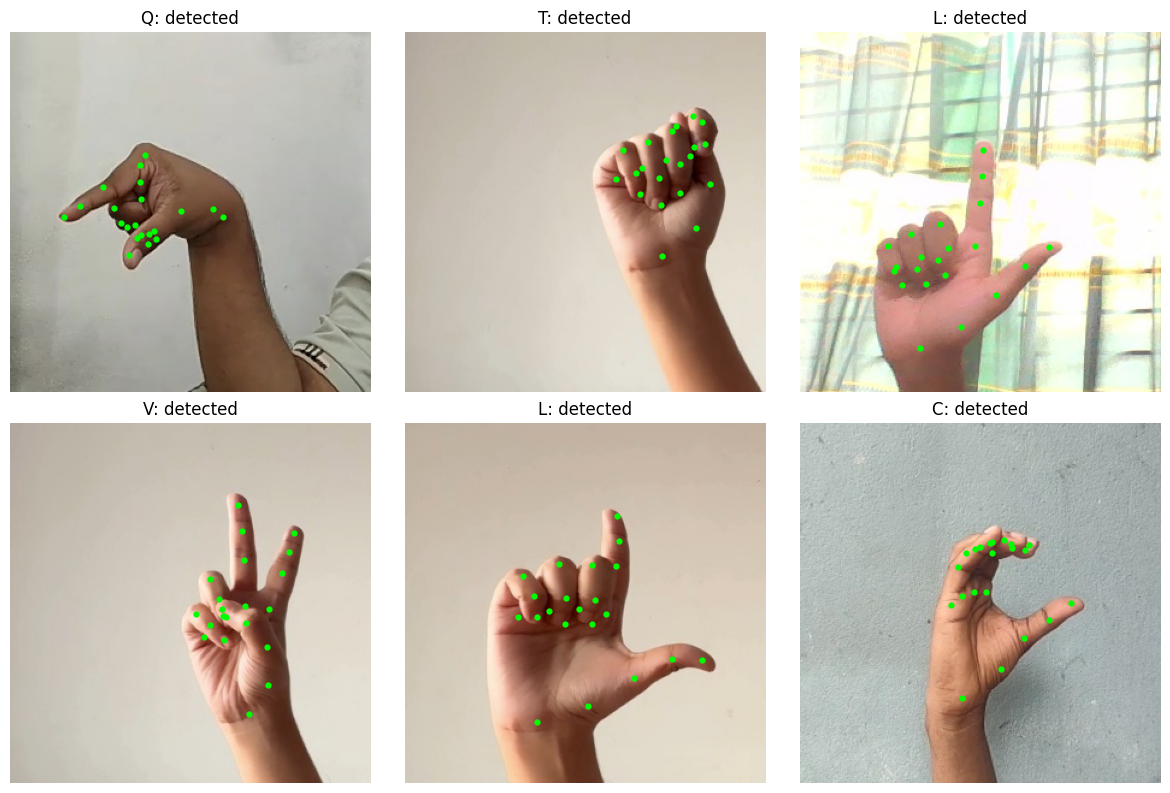

In [ ]:
train_paths, train_labels = find_images(TRAIN_ROOT)

sample_indices = np.random.default_rng(42).choice(
    len(train_paths),
    size=min(6, len(train_paths)),
    replace=False,
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax in axes.flat:
    ax.axis("off")

with create_landmarker() as landmarker:
    for ax, index in zip(axes.flat, sample_indices):
        rgb = read_rgb(train_paths[index])
        _, landmarks = get_features(rgb, landmarker)

        ax.imshow(rgb)

        if landmarks:
            height, width = rgb.shape[:2]
            ax.scatter(
                [point.x * width for point in landmarks],
                [point.y * height for point in landmarks],
                s=12,
                c="lime",
            )
            status = "detected"
        else:
            status = "NO HAND"

        ax.set_title(f"{LETTERS[train_labels[index]]}: {status}")

plt.tight_layout()
plt.show()

In [ ]:
train_indices, val_indices = train_test_split(
    np.arange(len(train_paths)),
    test_size=0.2,
    random_state=42,
    stratify=train_labels,
)

# Extract once, then select the corresponding rows.
features_all, training_failures = extract_features(train_paths)

X_train = features_all[train_indices]
y_train = train_labels[train_indices]

X_val = features_all[val_indices]
y_val = train_labels[val_indices]

train_ok = np.isfinite(X_train).all(axis=1)

print(f"Training hand detection: {train_ok.mean():.1%}")
print("First loading/detection failures:", training_failures[:3])

# All 24 classes must have usable training examples.
missing = set(range(24)) - set(y_train[train_ok])

if missing:
    raise ValueError(
        f"No usable training images for: {[LETTERS[i] for i in sorted(missing)]}"
    )

  0%|          | 0/24000 [00:00<?, ?it/s]

Training hand detection: 99.9%
First loading/detection failures: [('dataset/asl_dataset/H/P8_H_778.jpg', 'No usable hand landmarks'), ('dataset/asl_dataset/H/P8_H_780.jpg', 'No usable hand landmarks'), ('dataset/asl_dataset/H/P8_H_781.jpg', 'No usable hand landmarks')]


In [ ]:
classifier = XGBClassifier(
    objective="multi:softprob",
    num_class=24,
    n_estimators=250,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=4,
)

classifier.fit(
    X_train[train_ok],
    y_train[train_ok],
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=250, n_jobs=4, num_class=24, ...)

In [ ]:
def evaluate_pipeline(classifier, features, labels, name):
    usable = np.isfinite(features).all(axis=1)

    # -1 means no prediction; always incorrect for our letter labels.
    predictions = np.full(len(labels), -1, dtype=np.int64)

    if usable.any():
        predictions[usable] = classifier.predict(
            features[usable]
        ).astype(np.int64)

    print(f"\n{name}")
    print(f"Images: {len(labels)}")
    print(f"Usable hand detection: {usable.mean():.2%}")
    print(f"Overall accuracy: {(predictions == labels).mean():.2%}")

    if usable.any():
        accuracy = accuracy_score(
            labels[usable], predictions[usable]
        )
        print(f"Accuracy on detected hands: {accuracy:.2%}")

    return predictions


val_predictions = evaluate_pipeline(
    classifier, X_val, y_val, "Validation"
)

In [ ]:
external_paths, y_external = find_images(EXTERNAL_ROOT)

X_external, external_failures = extract_features(external_paths)

external_predictions = evaluate_pipeline(
    classifier,
    X_external,
    y_external,
    "ASLYset external evaluation",
)

  0%|          | 0/4800 [00:00<?, ?it/s]


ASLYset external evaluation
Images: 4800
Usable hand detection: 99.92%
Overall accuracy: 64.56%
Accuracy on detected hands: 64.62%


In [ ]:
import json
from pathlib import Path

output_dir = Path("models")
output_dir.mkdir(parents=True, exist_ok=True)

classifier.save_model(
    str(output_dir / "handspell_xgboost_v1.json")
)

metadata = {
    "letters": LETTERS,
    "feature_count": 63,
    "normalization": "wrist origin; wrist-to-middle-MCP distance",
    "external_accuracy": 0.6456,
}

(output_dir / "handspell_xgboost_v1_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("Model and metadata saved.")

Model and metadata saved.


In [ ]:
from google.colab import auth
auth.authenticate_user()

BUCKET_NAME = "handspell-asl-models-bucket"

# Run this immediately after training finishes
!gsutil -m cp -r models/ gs://{BUCKET_NAME}/
print("Securely uploaded to GCP before disconnect!")

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying file://models/handspell_xgboost_v1.json [Content-Type=application/json]...
Copying file://models/handspell_xgboost_v1_metadata.json [Content-Type=application/json]...
Copying file://models/hand_landmarker.task [Content-Type=application/octet-stream]...
-
Operation completed over 3 objects/12.7 MiB.                                     
Securely uploaded to GCP before disconnect!


In [ ]:
print(classification_report(
    y_external,
    external_predictions,
    labels=np.arange(24),
    target_names=list(LETTERS),
    digits=3,
    zero_division=0,
))

              precision    recall  f1-score   support

           A      0.722     0.805     0.761       200
           B      0.873     1.000     0.932       200
           C      0.750     0.570     0.648       200
           D      0.495     0.805     0.613       200
           E      0.625     1.000     0.769       200
           F      1.000     0.980     0.990       200
           G      0.582     0.530     0.555       200
           H      0.008     0.015     0.011       200
           I      0.972     0.870     0.918       200
           K      0.985     0.990     0.988       200
           L      1.000     0.885     0.939       200
           M      0.748     0.830     0.787       200
           N      0.341     0.690     0.456       200
           O      0.769     0.965     0.856       200
           P      0.000     0.000     0.000       200
           Q      0.571     0.020     0.039       200
           R      0.677     0.545     0.604       200
           S      0.649    

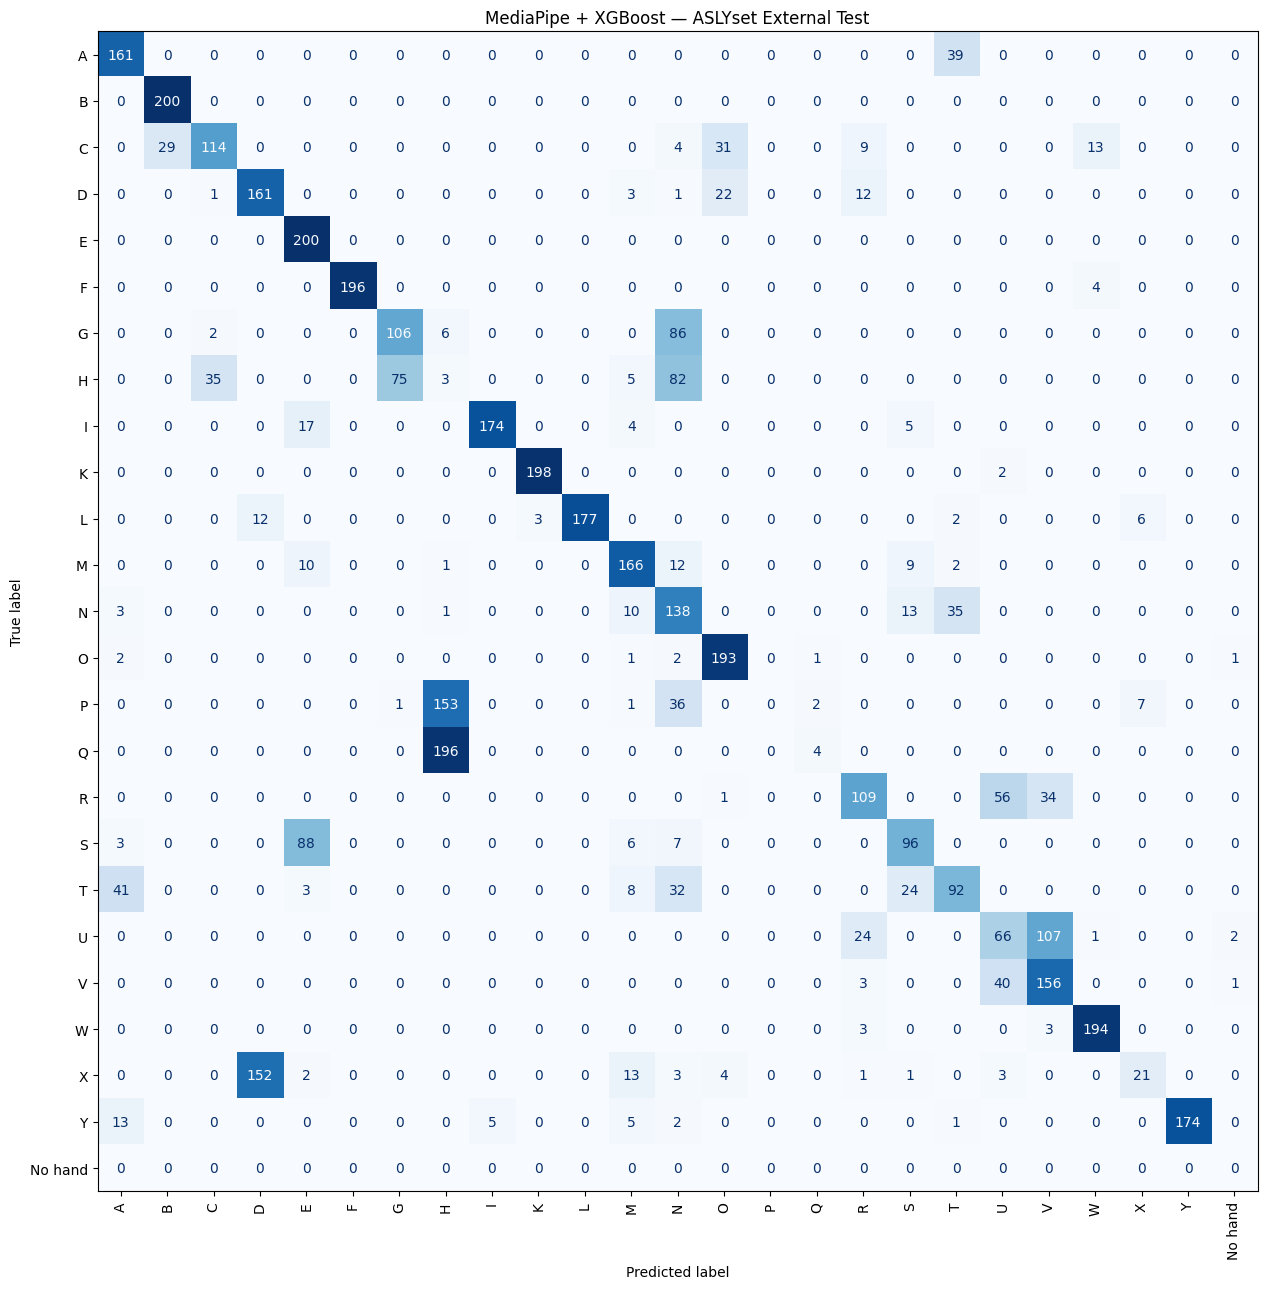

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Your existing 24-letter mapping.
LETTERS = "ABCDEFGHIKLMNOPQRSTUVWXY"

# Convert failure value -1 to index 24 for display.
predictions = np.where(
    external_predictions == -1,
    24,
    external_predictions,
)

display_labels = list(LETTERS) + ["No hand"]

matrix = confusion_matrix(
    y_external,
    predictions,
    labels=np.arange(25),
)

fig, ax = plt.subplots(figsize=(16, 13))

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=display_labels,
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=90,
    colorbar=False,
)

ax.set_title("MediaPipe + XGBoost — ASLYset External Test")
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import auth
auth.authenticate_user()

# Set your GCP project ID and a unique bucket name
PROJECT_ID = "kazim-wagon-bootcamp"
BUCKET_NAME = "handspell-asl-models-bucket"

# Create the bucket (only needed the first time)
!gcloud config set project {PROJECT_ID}
!gsutil mb -l us-central1 gs://{BUCKET_NAME}/

!gcloud config set project {PROJECT_ID}
# 1. Create a local models folder structure if it doesn't exist
import os
os.makedirs('models', exist_ok=True)

# 2. Upload your entire local models directory into your GCS bucket root
# (Note the exclamation mark '!' and curly braces '{BUCKET_NAME}' required by Colab)
!gsutil -m cp -r models/ gs://{BUCKET_NAME}/


print("All models and metadata successfully synced to Google Cloud Storage!")

Updated property [core/project].


To take a quick anonymous survey, run:
  $ gcloud survey

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Creating gs://handspell-asl-models-bucket/...
ServiceException: 409 A Cloud Storage bucket named 'handspell-asl-models-bucket' already exists. Try another name. Bucket names must be globally unique across all Google Cloud projects, including those outside of your organization.
Updated property [core/project].
Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying file://models/handspell_xgboost_v1.json [Content-Type=application/json

In [ ]:
!ls -l sample_data/

total 55504
-rwxr-xr-x 1 root root     1697 Jan  1  2000 anscombe.json
-rw-r--r-- 1 root root   301141 Sep 30 13:28 california_housing_test.csv
-rw-r--r-- 1 root root  1706430 Sep 30 13:28 california_housing_train.csv
-rw-r--r-- 1 root root 18289443 Sep 30 13:28 mnist_test.csv
-rw-r--r-- 1 root root 36523880 Sep 30 13:28 mnist_train_small.csv
-rwxr-xr-x 1 root root      962 Jan  1  2000 README.md
